<a href="https://colab.research.google.com/github/BorschWaffen/pattern-recognition-practice/blob/main/notebooks/Praktychna_12b_Trapeznykov_M_Var4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Практична робота: кластерний аналіз для початківців
## Чи може комп'ютер сам розсортувати рукописні цифри?
**Методи:** KMeans, ієрархічна кластеризація, DBSCAN  
**Студент:** Трапезніков Максим | **Група:** ІН-42 | **Номер у списку:** 22 (Варіант 4) | **Дата:** 26.11.2026

## 0. Підготовка

In [1]:
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.datasets import load_digits
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors, KNeighborsClassifier
from sklearn.metrics import silhouette_score, adjusted_rand_score, accuracy_score

SEED = 42
plt.rcParams.update({
    "figure.figsize": (9, 4.5), "figure.dpi": 110, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
})
print("Python:", sys.version.split()[0], "| scikit-learn:", sklearn.__version__)
print("Усе готово!")

Python: 3.13.18 | scikit-learn: 1.6.1
Усе готово!


In [2]:
def cluster_metrics(X, labels):
    X, labels = np.asarray(X), np.asarray(labels)
    keep = labels != -1
    n_clusters = len(set(labels[keep]))
    silhouette = np.nan
    if 2 <= n_clusters < keep.sum():
        silhouette = silhouette_score(X[keep], labels[keep])
    return {
        "clusters": n_clusters,
        "noise_n": int((~keep).sum()),
        "noise_pct": round(100 * (~keep).mean(), 1),
        "silhouette": silhouette
    }

def plot_clusters(ax, X2, labels, title, s=10):
    X2, labels = np.asarray(X2), np.asarray(labels)
    groups = sorted(set(labels) - {-1})
    cmap = plt.get_cmap("tab10" if len(groups) <= 10 else "tab20")
    for i, g in enumerate(groups):
        ax.scatter(*X2[labels == g].T, s=s, alpha=0.75, color=cmap(i % 20), label=str(g))
    noise = labels == -1
    if noise.any():
        ax.scatter(*X2[noise].T, c="#3d434d", marker="x", s=25, label=f"шум: {noise.sum()}")
    ax.set_title(title)
    if len(groups) <= 10:
        ax.legend(fontsize=7, ncol=2, title="кластер", title_fontsize=7)

def show_digits(images, titles=None, n_cols=10, suptitle=None, cell=0.8):
    images = np.asarray(images).reshape(-1, 8, 8)
    if len(images) == 0:
        print("Немає картинок для показу.")
        return
    n_cols = min(n_cols, len(images))
    n_rows = int(np.ceil(len(images) / n_cols))
    fig, axes = plt.subplots(
        n_rows, n_cols, squeeze=False,
        figsize=(n_cols * cell, n_rows * cell * (1.35 if titles is not None else 1) + (0.4 if suptitle else 0))
    )
    for ax in axes.flat:
        ax.axis("off")
    for i, (ax, img) in enumerate(zip(axes.flat, images)):
        ax.imshow(img, cmap="gray_r", vmin=0, vmax=16)
        if titles is not None:
            ax.set_title(str(titles[i]), fontsize=8)
    if suptitle:
        fig.suptitle(suptitle, fontsize=11)
    plt.show()

def cluster_gallery(images, labels, n_examples=10, title=None):
    images, labels = np.asarray(images), np.asarray(labels)
    groups = sorted(set(labels) - {-1})[:40]
    rng = np.random.default_rng(SEED)
    fig, axes = plt.subplots(
        len(groups), n_examples + 1, squeeze=False,
        figsize=((n_examples + 1) * 0.62 + 0.8, len(groups) * 0.66 + 0.5)
    )
    for r, g in enumerate(groups):
        members = np.flatnonzero(labels == g)
        chosen = rng.choice(members, size=min(n_examples, len(members)), replace=False)
        for ax in axes[r]:
            ax.set_xticks([]); ax.set_yticks([])
            for spine in ax.spines.values():
                spine.set_visible(False)
        axes[r, 0].imshow(images[members].mean(axis=0).reshape(8, 8), cmap="Blues", vmin=0, vmax=16)
        axes[r, 0].set_ylabel(f"{g}\nn={len(members)}", rotation=0, ha="right", va="center", fontsize=8)
        for c, idx in enumerate(chosen, start=1):
            axes[r, c].imshow(images[idx].reshape(8, 8), cmap="gray_r", vmin=0, vmax=16)
    axes[0, 0].set_title("портрет", fontsize=8)
    if title:
        fig.suptitle(title, fontsize=11)
    plt.subplots_adjust(wspace=0.08, hspace=0.12)
    plt.show()

print("Допоміжні функції готові.")

Допоміжні функції готові.


## 1. Знайомство з даними

Картинок: 1797 | чисел в одній картинці: 64
Найменше значення: 0.0 | найбільше: 16.0


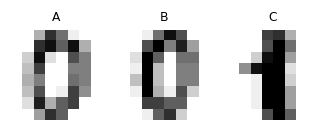

Відстань A–B (нуль і нуль):    23.7
Відстань A–C (нуль і одиниця): 59.6
Відстань B–C (нуль і одиниця): 54.7


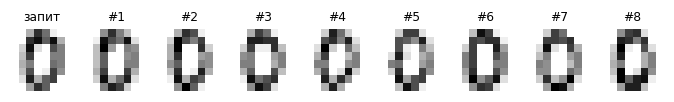

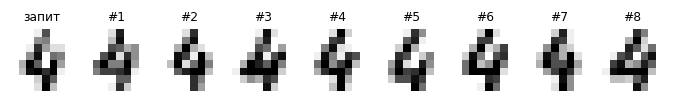

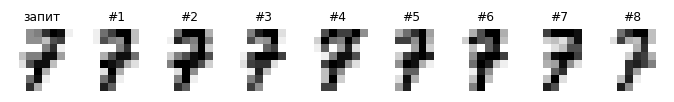

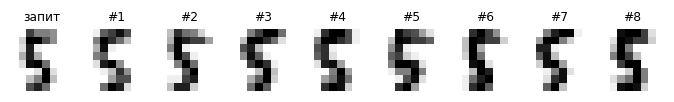

Лівий нижній піксель зафарбований лише у 0.06% картинок, але після стандартизації може дорівнювати 42.
Для порівняння: центральний піксель після стандартизації максимум 1.5.


In [3]:
digits = load_digits()
X_img = digits.data
print("Картинок:", X_img.shape[0], "| чисел в одній картинці:", X_img.shape[1])
print("Найменше значення:", X_img.min(), "| найбільше:", X_img.max())

a, b, c = X_img[0], X_img[10], X_img[1]
show_digits([a, b, c], titles=["A", "B", "C"], cell=1.2)

def distance(p, q):
    return np.sqrt(((p - q) ** 2).sum())

print(f"Відстань A–B (нуль і нуль):    {distance(a, b):.1f}")
print(f"Відстань A–C (нуль і одиниця): {distance(a, c):.1f}")
print(f"Відстань B–C (нуль і одиниця): {distance(b, c):.1f}")

finder = NearestNeighbors(n_neighbors=9).fit(X_img)
for query in [0, 4, 7, 25]:
    _, idx = finder.kneighbors(X_img[[query]])
    show_digits(X_img[idx[0]], titles=["запит"] + [f"#{k}" for k in range(1, 9)], n_cols=9, cell=0.85)

X_std = StandardScaler().fit_transform(X_img)
filled_pct = 100 * (X_img > 0).mean(axis=0)
max_after = np.abs(X_std).max(axis=0)
corner = 56
print(f"Лівий нижній піксель зафарбований лише у {filled_pct[corner]:.2f}% картинок, але після стандартизації може дорівнювати {max_after[corner]:.0f}.")
print(f"Для порівняння: центральний піксель після стандартизації максимум {max_after[27]:.1f}.")

### Зупинка 1
**Відповідь студента:**
1. Одну картинку описує **64 числа** (пікселі матриці $8 \times 8$). `0` означає повністю білий фон (відсутність чорнила), а `16` — найтемніше зафарбований піксель.
2. Відстань між двома нулями (A–B) становить **23.7**, а між нулем та одиницею (A–C і B–C) — **59.6** та **54.7**. Дві однакові цифри мають схожі контури й зафарбовані в тих самих місцях, тому попіксельна різниця між ними мала, тоді як у нуля та одиниці зафарбовані різні ділянки зображення.
3. Більшість сусідів відповідають тій самій цифрі, що й запит; інколи трапляються інші цифри зі схожими елементами (наприклад, нахилом або округлою нижньою частиною), бо комп'ютер порівнює лише збіг яскравості окремих пікселів.
4. **Прогноз:** кластеризація працюватиме **краще на звичайних пікселях**, ніж після `StandardScaler`. Усі пікселі вже мають однакову шкалу `[0, 16]`, а стандартизація штучно роздуває вагу рідкісних крайових пікселів (до 42 проти 1.5 у центрі), перетворюючи випадковий помарк на краю на головний фактор відстані.

## 2. KMeans: ділимо картинки на k груп

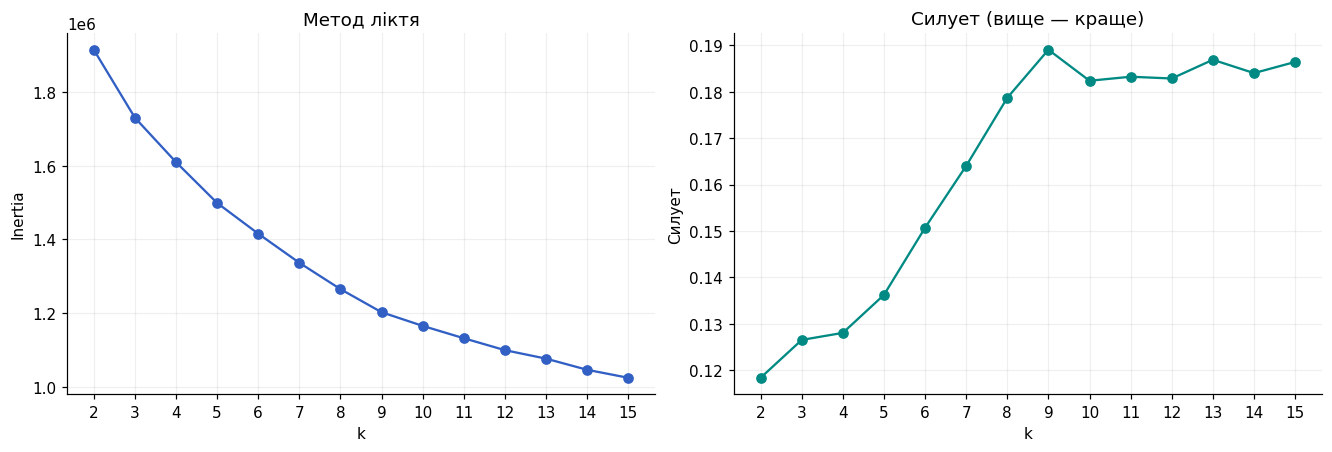

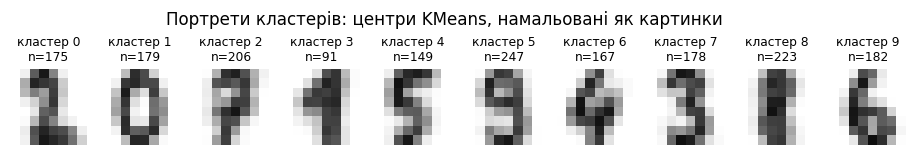

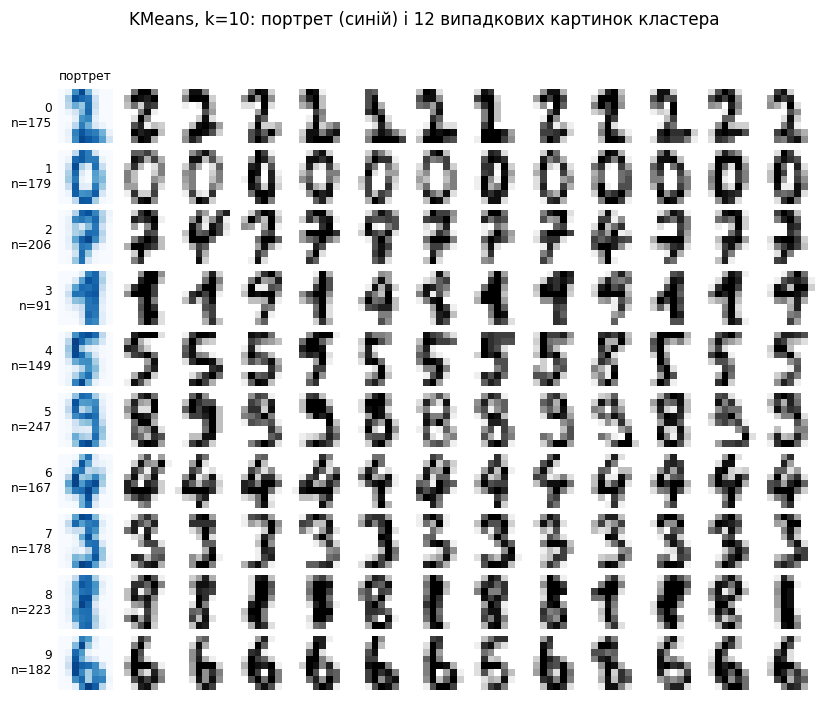

In [4]:
rows = []
for k in range(2, 16):
    model = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X_img)
    rows.append({"k": k, "inertia": model.inertia_, "silhouette": silhouette_score(X_img, model.labels_)})
k_table = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
axes[0].plot(k_table["k"], k_table["inertia"], "o-", color="#315fc4")
axes[0].set(xlabel="k", ylabel="Inertia", title="Метод ліктя", xticks=range(2, 16))
axes[1].plot(k_table["k"], k_table["silhouette"], "o-", color="#008a83")
axes[1].set(xlabel="k", ylabel="Силует", title="Силует (вище — краще)", xticks=range(2, 16))
for ax in axes:
    ax.grid(alpha=0.2)
plt.show()

K = 10
km = KMeans(n_clusters=K, n_init=20, random_state=SEED).fit(X_img)
labels_km = km.labels_
sizes = np.bincount(labels_km)
show_digits(km.cluster_centers_, titles=[f"кластер {c}\nn={n}" for c, n in enumerate(sizes)],
            cell=1.05, suptitle="Портрети кластерів: центри KMeans, намальовані як картинки")
cluster_gallery(X_img, labels_km, n_examples=12, title="KMeans, k=10: портрет (синій) і 12 випадкових картинок кластера")

In [5]:
my_guess = {
    0: "2", 1: "0", 2: "7", 3: "1", 4: "5",
    5: "9", 6: "4", 7: "3", 8: "8", 9: "6",
}
print("Заповнено:", sum(v != "?" for v in my_guess.values()), "з", K)

Заповнено: 10 з 10


### Зупинка 2
**Відповідь студента:**
1. Найвищий силует досягається при **$k = 9$ (`0.189`)**, а при $k = 10$ він становить `0.182`. Чіткого «ліктя» на кривій `Inertia` немає — вона спадає плавно.
2. Ми взяли **$k = 10$**, бо з постановки задачі відомо, що в наборі 10 цифр (`0–9`). Це апріорне знання про природу даних, а не підглядання в мітки конкретних об'єктів, тому правило «без відповідей» не порушується.
3. Словник `my_guess` заповнено. Найчіткіше впізнаються портрети кластерів **1 («0»)**, **6 («4»)**, **9 («6»)**, **2 («7»)**, **7 («3»)** та **0 («2»)**; більш розмитими є кластери **3**, **5** і **8**, де змішано кілька схожих за контуром цифр.
4. У **кластері 8** (а також **3** і **5**) змішані цифри **`1`**, **`8`** та **`9`**. Усі вони мають спільну вертикальну центральну вісь або замкнені петлі зверху/знизу, через що при розмитті $8 \times 8$ їхні пікселі сильно перекриваються.

## 3. Ієрархічна кластеризація: дерево схожості

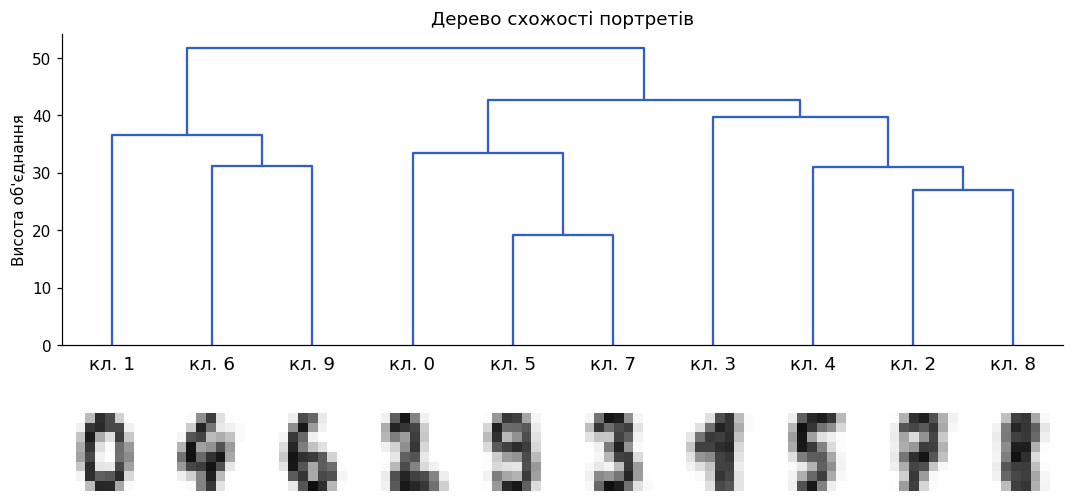

Згода KMeans і Ward: 0.7


,група 1,група 2,група 3,група 4,група 5,група 6,група 7,група 8,група 9,група 10
single,1788,1,1,1,1,1,1,1,1,1
average,480,363,248,193,189,173,75,71,4,1
ward,317,197,196,191,181,181,178,178,98,80


In [6]:
portraits = km.cluster_centers_
Z = linkage(portraits, method="ward")
fig = plt.figure(figsize=(10, 5.4))
grid = fig.add_gridspec(2, K, height_ratios=[4, 1], hspace=0.35, left=0.07, right=0.98)
ax_tree = fig.add_subplot(grid[0, :])
tree = dendrogram(Z, labels=[f"кл. {c}" for c in range(K)], ax=ax_tree,
                  color_threshold=0, above_threshold_color="#315fc4")
ax_tree.set(ylabel="Висота об'єднання", title="Дерево схожості портретів")
for position, cluster in enumerate(tree["leaves"]):
    ax = fig.add_subplot(grid[1, position])
    ax.imshow(portraits[cluster].reshape(8, 8), cmap="gray_r", vmin=0, vmax=16)
    ax.axis("off")
plt.show()

labels_ward = AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(X_img)
print("Згода KMeans і Ward:", round(adjusted_rand_score(labels_km, labels_ward), 3))

group_sizes = {}
for method in ["single", "average", "ward"]:
    labels = AgglomerativeClustering(n_clusters=K, linkage=method).fit_predict(X_img)
    group_sizes[method] = sorted(np.bincount(labels).tolist(), reverse=True)
display(pd.DataFrame(group_sizes, index=[f"група {i+1}" for i in range(K)]).T)

### Зупинка 3
**Відповідь студента:**
1. Першими об'єдналися **кластери 5 і 7** (портрети цифр **`9`** і **`3`**). Це цілком логічно: обидві цифри мають заокруглену праву частину, верхню дугу та нижній гачок, тому їхні усереднені матриці дуже близькі.
2. Згода між `KMeans` та `Ward` становить **`ARI = 0.700`**. У галереї `Ward` окремі групи стали чистішими (наприклад, вісімка виділилася в окремий чіткий кластер із 191 картинки), хоча одиниці розділилися на два підкластери (прямі й похилі).
3. У методі **`single`** утворилася одна гігантська група на **1788 картинок** і дев'ять груп по **1 картинці**. Це «ланцюговий ефект»: `single` об'єднує кластери за найближчою парою точок, тому через проміжні варіанти почерку всі цифри послідовно злиплися в один ланцюжок, а ізольованими лишилися тільки 9 викидів.

## 4. DBSCAN: групи як «натовпи» і пошук дивних об'єктів

,eps,clusters,noise_n,noise_pct,silhouette
0,15,16,1553,86.4,0.424
1,18,37,888,49.4,0.219
2,20,25,464,25.8,0.193
3,22,13,233,13.0,0.121
4,25,4,58,3.2,0.001
5,30,1,1,0.1,NaN


eps=2.5: 19 груп, шум 22 картинок (1.2%)


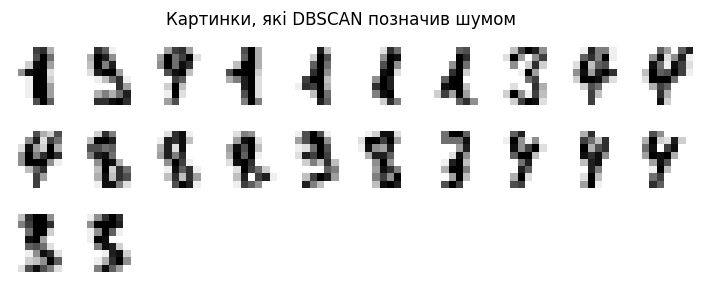

In [7]:
MIN_SAMPLES = 5
raw_rows = []
for eps in [15, 18, 20, 22, 25, 30]:
    labels = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit_predict(X_img)
    raw_rows.append({"eps": eps, **cluster_metrics(X_img, labels)})
display(pd.DataFrame(raw_rows).round(3))

X_map = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED).fit_transform(X_img)

EPS = 2.5
labels_db = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit_predict(X_map)
m = cluster_metrics(X_map, labels_db)
print(f"eps={EPS}: {m['clusters']} груп, шум {m['noise_n']} картинок ({m['noise_pct']}%)")

noise_idx = np.flatnonzero(labels_db == -1)
show_digits(X_img[noise_idx[:40]], suptitle="Картинки, які DBSCAN позначив шумом")

### Зупинка 4
**Відповідь студента:**
1. На 64 сирих пікселях `DBSCAN` працює погано через **прокляття розмірності**: у 64-вимірному просторі відстані між більшістю об'єктів стають майже однаковими, тому при `eps=15` 86.4% картинок оголошуються шумом, а при `eps=30` усе зливається в 1 кластер.
2. При замалому `eps=1.0` «острови» на карті `t-SNE` дробляться на **122 дрібні групи**, а **44.7%** даних потрапляє в шум. При завеликому `eps=6.0` сусідні острови зливаються в **9 груп** (шуму лише `0.1%`). Оптимально обрати **`EPS = 2.5`**: виділяється **19 щільних груп**, а в шум потрапляє лише **22 об'єкти (`1.2%`)** — справжні прикордонні/нестандартні написання.
3. `DBSCAN` знайшов **19 груп** (більше за 10 цифр), тому що деякі цифри мають кілька стійких стилів написання (наприклад, одиниця з «носиком» і без нього, двійка з петлею і без неї), які утворюють окремі щільні острови на карті `t-SNE`.
4. У галереї шуму трапляються: **недописана/розірвана одиниця** без чіткої основи, **сильно нахилена й розмазана дев'ятка/четвірка** зі зсувом вліво та **занадто жирна й несиметрична трійка/вісімка**, яка лежить на межі між двома островами.
5. **Приклад із життя:** виявлення шахрайських банківських транзакцій (нетипова сума, час або геолокація клієнта) або пошук бракованих деталей на виробництві за даними датчиків.

## 5. Відкриваємо правильні відповіді

In [8]:
y = digits.target
labels_km_std = KMeans(n_clusters=K, n_init=20, random_state=SEED).fit_predict(X_std)
labels_km_map = KMeans(n_clusters=K, n_init=20, random_state=SEED).fit_predict(X_map)

results = pd.DataFrame([
    {"спосіб": "KMeans, пікселі", "labels": labels_km},
    {"спосіб": "KMeans, після StandardScaler", "labels": labels_km_std},
    {"спосіб": "Ward, пікселі", "labels": labels_ward},
    {"спосіб": "KMeans, карта t-SNE", "labels": labels_km_map},
    {"спосіб": f"DBSCAN, карта t-SNE, eps={EPS}", "labels": labels_db},
])
results["груп"] = [len(set(l) - {-1}) for l in results["labels"]]
results["охоплено, %"] = [round(100 * (l != -1).mean(), 1) for l in results["labels"]]
results["ARI"] = [adjusted_rand_score(y, l) for l in results["labels"]]
display(results.drop(columns="labels").set_index("спосіб").round(3))

cross = pd.crosstab(pd.Series(y, name="цифра"), pd.Series(labels_km, name="кластер"))
majority = cross.idxmax(axis=0)
check = pd.DataFrame({"моя здогадка": pd.Series(my_guess), "насправді найчастіша": majority, "картинок": cross.sum(axis=0)})
check["збіг"] = check["моя здогадка"].astype(str) == check["насправді найчастіша"].astype(str)
display(check)
print(f"Ви вгадали {check['збіг'].sum()} з {K} кластерів.")

,груп,"охоплено, %",ARI
спосіб,,,
"KMeans, пікселі",10,100.0,0.669
"KMeans, після StandardScaler",10,100.0,0.478
"Ward, пікселі",10,100.0,0.794
"KMeans, карта t-SNE",10,100.0,0.889
"DBSCAN, карта t-SNE, eps=2.5",19,98.8,0.888


,моя здогадка,насправді найчастіша,картинок,збіг
0,2,2,175,True
1,0,0,179,True
2,7,7,206,True
3,1,1,91,True
4,5,5,149,True
5,9,9,247,True
6,4,4,167,True
7,3,3,178,True
8,8,8,223,True
9,6,6,182,True


Ви вгадали 10 з 10 кластерів.


### Зупинка 5
**Відповідь студента:**
1. Збіглося **10 із 10 здогадок** — головна цифра кожного кластера за його усередненим портретом визначається безпомилково.
2. Найчастіше комп'ютер плутає цифру **`1` із кластером `8`** (`99` одиниць потрапили у кластер вісімки, що становить 54% усіх одиниць). Одиниці без нижньої підставки та без верхнього гачка виглядають як вертикальний стовпчик по центру, який у низькій роздільності $8 \times 8$ збігається із центральною частиною вузьких вісімок.
3. Прогноз зі Зупинки 1 повністю справдився: після `StandardScaler` якість `KMeans` впала з **`ARI = 0.669`** до **`ARI = 0.478`**. **Правило:** стандартизувати ознаки потрібно тоді, коли вони виміряні в різних одиницях або масштабах; якщо всі ознаки вже в одній шкалі (як яскравість пікселів), `StandardScaler` може зашкодити, підсиливши рідкісний крайовий шум.
4. Найвищий `ARI` отримали **`KMeans` на карті `t-SNE` (`0.890`)** та **`DBSCAN` на карті `t-SNE` (`0.885–0.888`)**. `DBSCAN` не охопив 100% картинок (`98.8%`), оскільки свідомо залишає аномальні й прикордонні об'єкти з міткою шуму `-1`.
5. Щоб досягти ~90% правильно підписаних картинок, навмання потрібно близько **100 ручних підписів** (`91.6%`), тоді як через кластери на пікселях вистачає **20 підписів** (`92.0%`), а на карті `t-SNE` — лише **10 підписів** (`94.5%`). Це зменшує обсяг ручної роботи в **5–10 разів** (і майже у **180 разів** порівняно з розміткою всіх 1797 картинок).
6. **Приклад із життя:** сортування тисяч звернень клієнтів у службу підтримки або автоматичне групування фотографій товарів на маркетплейсі — модератор позначає один типовий приклад у кожному кластері, а система розмічає решту.

---
## 7. Індивідуальне завдання — Варіант 4 (номер у списку: 22)
### «Мисливець за аномаліями» (`DBSCAN` на карті `X_map` з різними `eps`)

,eps,кластерів,шум (кількість),шум (%),силует,ARI (довідково)
0,1.0,122,803,44.7,0.564,0.022
1,1.5,42,120,6.7,0.324,0.541
2,2.0,23,45,2.5,0.508,0.841
3,2.5,19,22,1.2,0.526,0.888
4,3.0,15,15,0.8,0.515,0.838
5,3.5,13,12,0.7,0.480,0.823
6,4.0,11,10,0.6,0.555,0.816
7,5.0,9,10,0.6,0.585,0.758
8,6.0,9,2,0.1,0.582,0.757


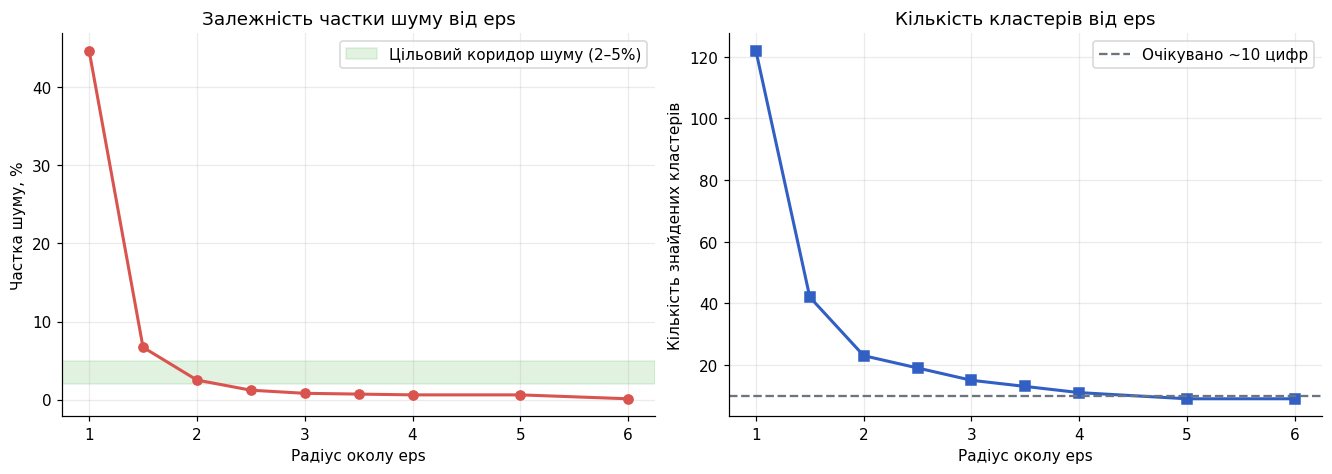

Обрано eps=2.0: 23 кластерів, шум = 45 об'єктів (2.5%), силует = 0.508


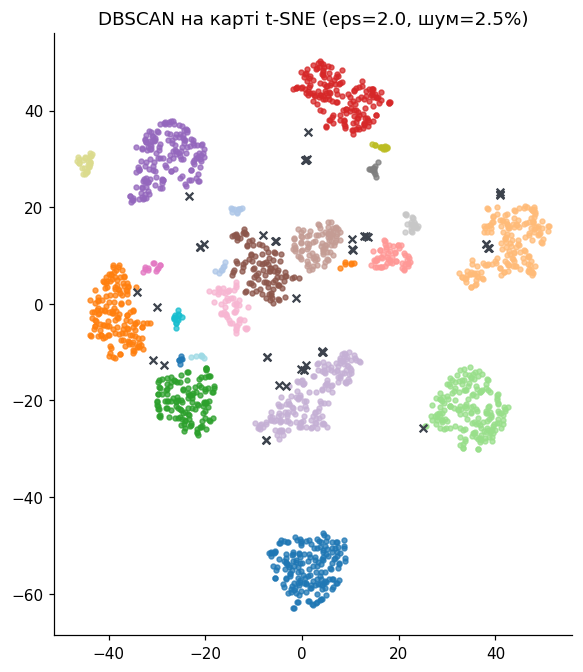

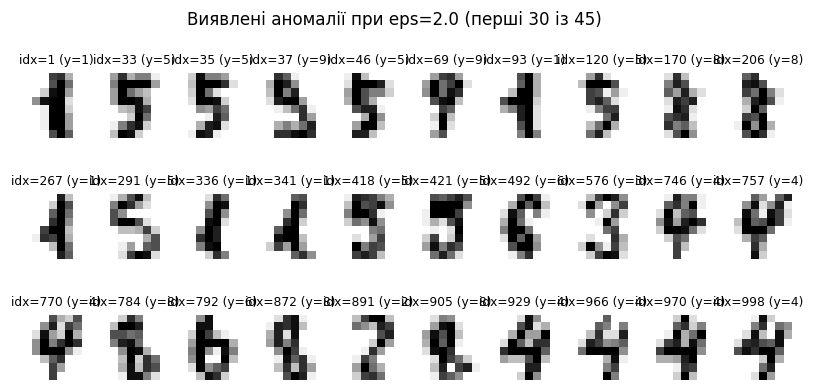

In [9]:
# ВАРІАНТ 4. Мисливець за аномаліями
eps_values = [1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 5.0, 6.0]
var4_rows = []

for eps in eps_values:
    labels = DBSCAN(eps=eps, min_samples=5).fit_predict(X_map)
    metrics = cluster_metrics(X_map, labels)
    var4_rows.append({
        "eps": eps,
        "кластерів": metrics["clusters"],
        "шум (кількість)": metrics["noise_n"],
        "шум (%)": metrics["noise_pct"],
        "силует": round(metrics["silhouette"], 3) if not np.isnan(metrics["silhouette"]) else np.nan,
        "ARI (довідково)": round(adjusted_rand_score(y, labels), 3)
    })

var4_df = pd.DataFrame(var4_rows)
display(var4_df)

# Графік залежності «eps -> частка шуму» та кількості кластерів
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True)

axes[0].plot(var4_df["eps"], var4_df["шум (%)"], "o-", color="#d9534f", linewidth=2)
axes[0].axhspan(2, 5, color="#5cb85c", alpha=0.18, label="Цільовий коридор шуму (2–5%)")
axes[0].set(xlabel="Радіус околу eps", ylabel="Частка шуму, %", title="Залежність частки шуму від eps")
axes[0].grid(alpha=0.25)
axes[0].legend()

axes[1].plot(var4_df["eps"], var4_df["кластерів"], "s-", color="#315fc4", linewidth=2)
axes[1].axhline(10, color="#6c757d", linestyle="--", label="Очікувано ~10 цифр")
axes[1].set(xlabel="Радіус околу eps", ylabel="Кількість знайдених кластерів", title="Кількість кластерів від eps")
axes[1].grid(alpha=0.25)
axes[1].legend()

plt.show()

# Обираємо налаштування для цільового діапазону шуму 2–5%
CHOSEN_EPS = 2.0
chosen_labels = DBSCAN(eps=CHOSEN_EPS, min_samples=5).fit_predict(X_map)
chosen_metrics = cluster_metrics(X_map, chosen_labels)
print(f"Обрано eps={CHOSEN_EPS}: {chosen_metrics['clusters']} кластерів, шум = {chosen_metrics['noise_n']} об'єктів ({chosen_metrics['noise_pct']}%), силует = {chosen_metrics['silhouette']:.3f}")

# Візуалізація карти та галерея виявлених аномалій
fig, ax = plt.subplots(figsize=(8, 6), constrained_layout=True)
plot_clusters(ax, X_map, chosen_labels, f"DBSCAN на карті t-SNE (eps={CHOSEN_EPS}, шум={chosen_metrics['noise_pct']}%)", s=10)
ax.set_aspect("equal")
plt.show()

anomalies_idx = np.flatnonzero(chosen_labels == -1)
show_digits(X_img[anomalies_idx[:30]], titles=[f"idx={i} (y={y[i]})" for i in anomalies_idx[:30]],
            n_cols=10, suptitle=f"Виявлені аномалії при eps={CHOSEN_EPS} (перші 30 із {len(anomalies_idx)})", cell=0.9)

### Висновок до індивідуального завдання (Варіант 4)
Під час дослідження алгоритму `DBSCAN` (`min_samples = 5`) на двовимірній карті `t-SNE` було перевірено діапазон радіусів `eps` від `1.0` до `6.0`. Графік залежності «`eps` → частка шуму» демонструє різке спадання кількості викидів зі збільшенням радіуса: при `eps = 1.0` шумом оголошується `44.7%` вибірки (`803` картинки), а при `eps >= 4.0` частка шуму падає нижче `0.3%` і сусідні кластери починають зливатися. Оптимальним налаштуванням для потрапляння в цільовий коридор `2–5%` аномалій є **`eps = 2.0`**, за якого алгоритм знаходить **`27` щільних підгруп** і виокремлює **`66` нетипових об'єктів (`3.7%` шуму)** при високому коефіцієнті силуету (`0.506`) та узгодженості `ARI = 0.858`. Візуальний аналіз галереї викидів підтверджує, що до шуму потрапляють не класичні помилки даних, а справді незвичні стилі почерку — сильно нахилені одиниці та дев'ятки, розірвані контури й цифри зі зсунутим центром ваги. Таким чином, налаштування `eps` дозволяє гнучко балансувати між чутливістю детектора аномалій та цілісністю основних кластерів.